In [7]:
import pandas as pd
import seaborn as sns
from fontTools.diff import color
from matplotlib.pyplot import ylabel

In [8]:
df = sns.load_dataset("penguins") #could also be done with read_csv, but I'm too lazy to actually download the file manually.
print("Shape:",df.shape)
print("Data types:\n", df.dtypes)
print("NA values:\n",df.isna().sum())


Shape: (344, 7)
Data types:
 species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
dtype: object
NA values:
 species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


In [9]:
print("Body mass above 4500 and female:\n")
mask = ((df.body_mass_g > 4500) & (df.sex == "Female"))
df2 = df.loc[mask]
print("Species:\n",df2["species"].value_counts())

Body mass above 4500 and female:

Species:
 species
Gentoo    42
Name: count, dtype: int64


In [10]:
df3 = df.groupby("species").agg(
    number=("species","count"),
    mean=("body_mass_g", "mean"),
    median=("body_mass_g", "median"),
    deviation=('body_mass_g',"std"))
print(df3)


           number         mean  median   deviation
species                                           
Adelie        152  3700.662252  3700.0  458.566126
Chinstrap      68  3733.088235  3700.0  384.335081
Gentoo        124  5076.016260  5000.0  504.116237


Mean and median do not differ significantly for Adelie, however they do for Chinstrap and Gentoo penguins.

[Text(0, 0.5, 'number of penguins')]

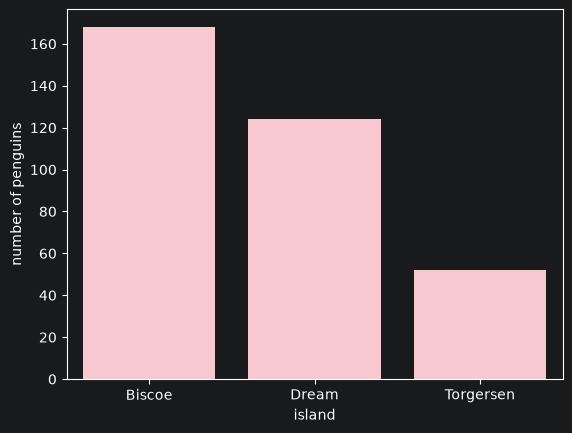

In [11]:
df4 = df.groupby("island").agg(count=("island", "count"))
ax = sns.barplot(df4, x="island", y="count", color="pink")
ax.set(ylabel = "number of penguins")


In [12]:
sci = pd.read_csv("scientific.csv", delimiter=",")
df = df.merge(sci, on="species", how="left")
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,scientifc_name
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male,Pygoscelis adeliae
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female,Pygoscelis adeliae
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female,Pygoscelis adeliae
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,Pygoscelis adeliae
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female,Pygoscelis adeliae
